In [1]:
import osmnx as ox
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
import matplotlib.patheffects as path_effects

In [2]:
cities = {    
    "Grammichele": (37.2140, 14.6366),
    "Brussels": (50.84172, 4.36222),
    "Palmanova": (45.9055, 13.3094),     
    "Venice": (45.4451, 12.3286),
    "Durrat al Bahrain": (25.83387, 50.613617),   
    "Mannheim": (49.4883, 8.4662),       
    "Neuf-Brisach": (48.0178, 7.5277),
    "Washington DC": (38.9096, -77.0434),
    "Fez": (34.0645, -4.9747),
}

In [3]:
# OSM data

radius = 700

city_data = {}

for city, (lat, lon) in cities.items():    

    # Roads
    graph = ox.graph_from_point((lat, lon), dist=radius + 100, network_type="all", simplify=True)
    edges = ox.graph_to_gdfs(graph, nodes=False)

    # Buildings
    buildings = ox.features_from_point((lat, lon), tags={"building": True}, dist=radius + 100)

    # Center point
    center = gpd.GeoSeries([Point(lon, lat)], crs="EPSG:4326")

    # Reproject to metric 
    crs = center.estimate_utm_crs()
    center = center.to_crs(crs)
    edges = edges.to_crs(crs)
    buildings = buildings.to_crs(crs)

    # Buffer + clipping
    buffer = center.buffer(radius)
    edges = gpd.clip(edges, buffer)
    buildings = gpd.clip(buildings, buffer)

    # Building polygons
    buildings = buildings[buildings.geometry.geom_type.isin(["Polygon", "MultiPolygon"])]

    # Data dict
    city_data[city] = {
        "edges": edges,
        "buildings": buildings,
        "center": center,
        "crs": crs
    }    

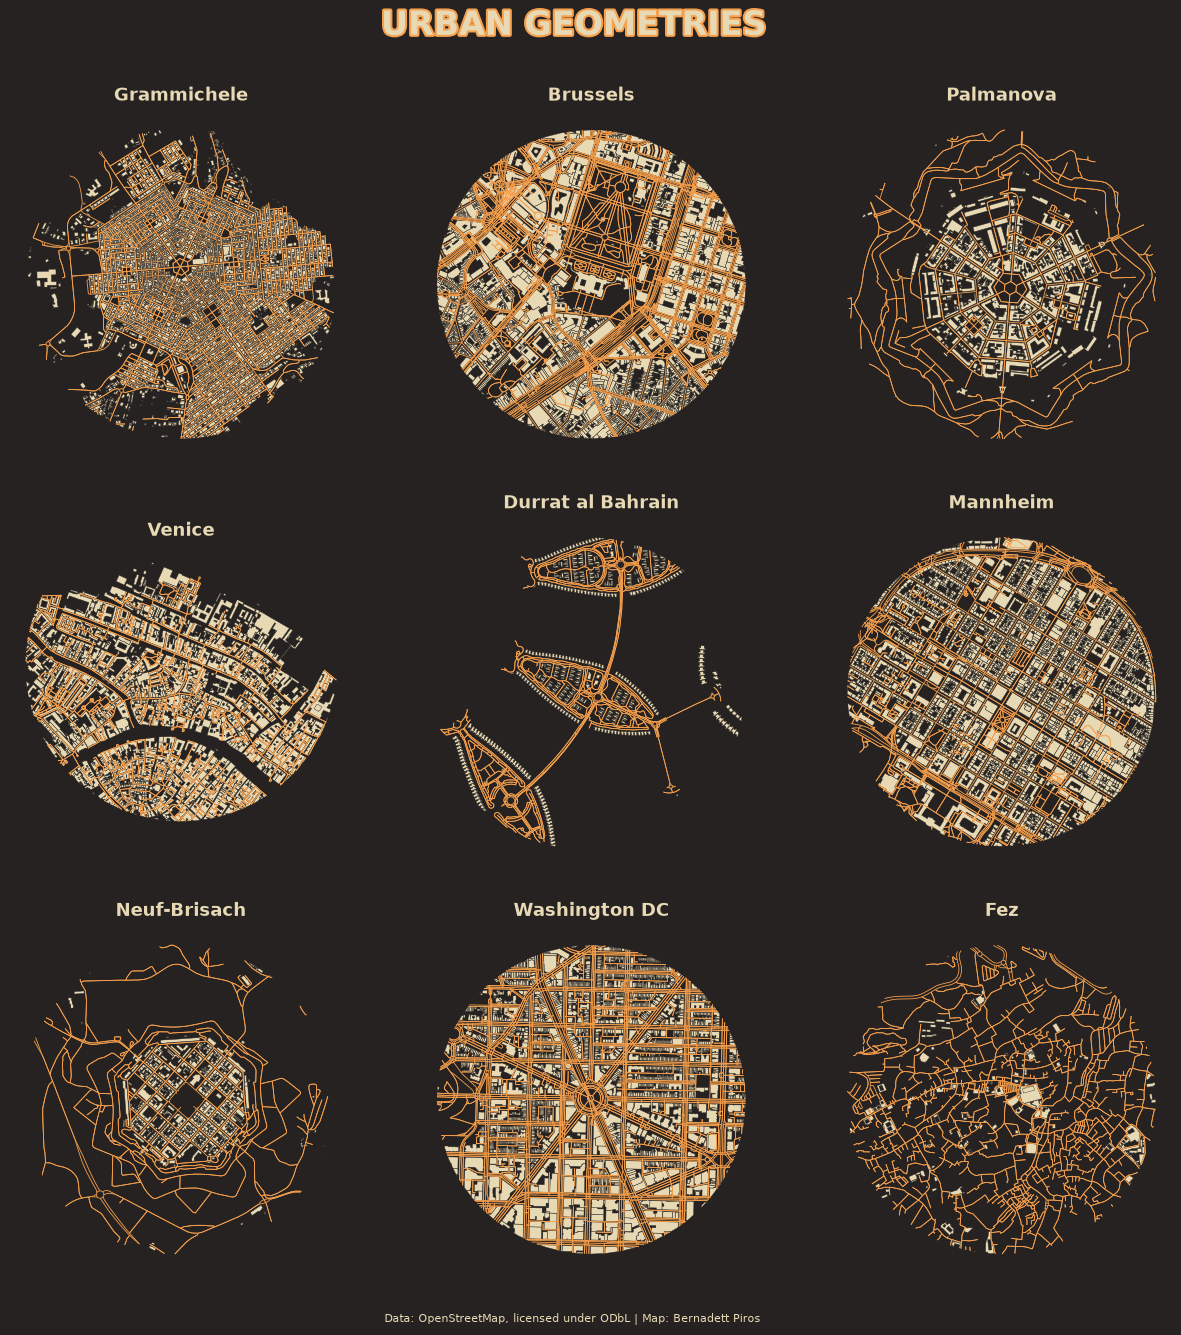

In [4]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 15), facecolor="#252221")

axes = axes.flatten()

# Cities
for ax, (city, data) in zip(axes, city_data.items()):    

    # Buildings
    data["buildings"].plot(ax=ax, color="#E8D9B5", ec="#252221", lw=0.3, zorder=2)

    # Roads
    data["edges"].plot(ax=ax, color="#F6A04D", lw=0.6, zorder=3)

    # Subplot title
    ax.set_title(city, color="#E8D9B5", size=13, weight="bold", pad=10)    

    ax.set_aspect("equal")
    ax.set_facecolor("#252221")
    ax.axis("off")

# Title
title=fig.text(0.5, 0.95,
               "URBAN GEOMETRIES",
               color="#E8D9B5", size=24, weight="bold", ha="center", va="top")   
title.set_path_effects([path_effects.Stroke(linewidth=3, foreground="#F6A04D"), path_effects.Normal()])

# Caption
fig.text(0.5, 0.075, 
         "Data: OpenStreetMap, licensed under ODbL | Map: Bernadett Piros", 
         color="#E8D9B5", size=8, ha="center")

plt.show()

#fig.savefig("urban_geometries.png", bbox_inches="tight", pad_inches=0.2)